# 02. Engenharia de Atributos e Calendário Operacional (2024–2027)

**Etapa CRISP-DM:** Preparação dos Dados (*Feature Engineering*)

### O que construímos nesta etapa
1. **Calendário Operacional 2024–2027** com feriados nacionais, estaduais de Goiás e municipais de Goiânia + Carnaval/Corpus Christi, aplicando a regra exata de pesos (`Dia Útil = 1,0`, `Sábado = 0,5`, `Domingo/Feriado = 0,0`).
2. **Variáveis estruturais e causais** (sem vazamento do futuro):
   - Para **Vendas**: `dias_uteis_ponderados`, `qtd_bairros_ativos_mes`, `qtd_canais_ativos_mes`, `vendas_por_du_lag1` / `vendas_lag1`, sazonalidade trigonométrica (`mes_sin`, `mes_cos`).
   - Para **Retiradas**: `dias_uteis_ponderados`, `carteira_inicio_mes` (base exposta ao churn), `vendas_acum_3m_ant` (safras jovens M1–M3 com maior propensão a churn/FPD), `retiradas_lag1` (limpo de anomalias de lote) e sazonalidade.
3. **Análise de Correlação e Multicolinearidade (VIF)** para orientar a escolha entre OLS puro e Regressão Linear Regularizada (Ridge / Lasso / ElasticNet).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.outliers_influence import variance_inflation_factor

ROOT = Path("..").resolve()
DATA_PROC = ROOT / "data" / "processed"
FIG_DIR = ROOT / "reports" / "figures"

sns.set_theme(style="whitegrid")

df_cal_mensal = pd.read_parquet(DATA_PROC / "calendario_mensal.parquet")
df_ml = pd.read_parquet(DATA_PROC / "serie_mensal_ml.parquet")
df_closed = df_ml[df_ml["mes_fechado"]].copy()

print("=== CALENDÁRIO OPERACIONAL DE 2027 (PESOS 1,0 / 0,5 / 0,0) ===")
cal_2027 = df_cal_mensal[df_cal_mensal["ano"] == 2027].copy()
display(cal_2027[[
    "anomes", "dias_calendario", "dias_uteis_cheios", "sabados_uteis",
    "domingos", "feriados_em_dia_util", "dias_uteis_ponderados"
]])
print(f"Total de Dias Úteis Ponderados em 2027: {cal_2027['dias_uteis_ponderados'].sum():.1f}")


=== CALENDÁRIO OPERACIONAL DE 2027 (PESOS 1,0 / 0,5 / 0,0) ===


,anomes,dias_calendario,dias_uteis_cheios,sabados_uteis,domingos,feriados_em_dia_util,dias_uteis_ponderados
36,2027-01,31,20,5,5,1,22.5
37,2027-02,28,18,4,4,2,20.0
38,2027-03,31,22,4,4,1,24.0
39,2027-04,30,21,4,4,1,23.0
40,2027-05,31,19,4,5,2,21.0
41,2027-06,30,22,4,4,0,24.0
42,2027-07,31,21,5,4,1,23.5
43,2027-08,31,22,4,5,0,24.0
44,2027-09,30,21,4,4,1,23.0
45,2027-10,31,20,5,5,1,22.5


Total de Dias Úteis Ponderados em 2027: 273.5


## 1. Matriz de Correlação — Drivers de Vendas e Retiradas

Verificamos as correlações lineares (Pearson) entre os alvos (`vendas`, `vendas_por_du`, `retiradas`) e as variáveis estruturais/causais nos meses fechados (excluindo os dois meses de baixa em lote ao avaliar retiradas).

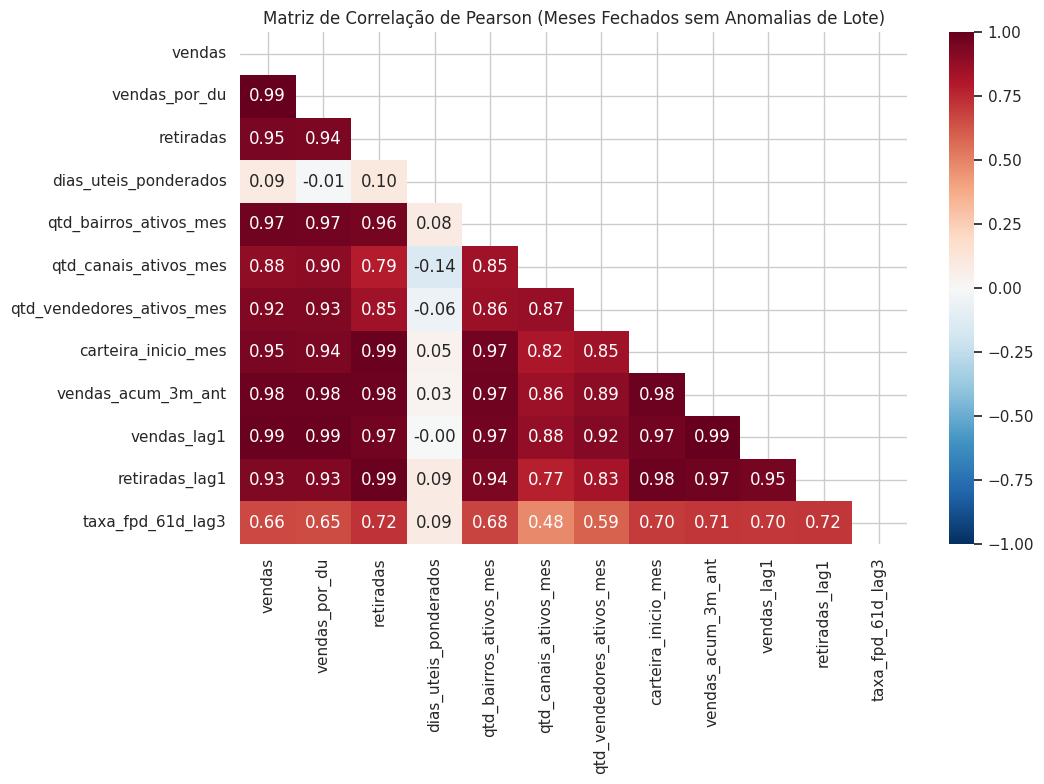

In [2]:
cols_corr = [
    "vendas", "vendas_por_du", "retiradas",
    "dias_uteis_ponderados", "qtd_bairros_ativos_mes", "qtd_canais_ativos_mes",
    "qtd_vendedores_ativos_mes", "carteira_inicio_mes", "vendas_acum_3m_ant",
    "vendas_lag1", "retiradas_lag1", "taxa_fpd_61d_lag3"
]
df_clean_corr = df_closed[df_closed["anomalia_retirada"] == 0][cols_corr].dropna()
corr_mat = df_clean_corr.corr()

fig, ax = plt.subplots(figsize=(11, 8))
mask = np.triu(np.ones_like(corr_mat, dtype=bool))
sns.heatmap(corr_mat, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Matriz de Correlação de Pearson (Meses Fechados sem Anomalias de Lote)")
plt.tight_layout()
plt.savefig(FIG_DIR / "02_matriz_correlacao.png", dpi=140)
plt.show()


## 2. Relações Lineares Principais e Diagnóstico de Multicolinearidade (VIF)

Um cuidado clássico em Regressão Linear é medir o **VIF (*Variance Inflation Factor*)**. Quando variáveis estruturais crescem juntas no tempo (ex.: `carteira_inicio_mes` e `vendas_acum_3m_ant`, ou `qtd_bairros_ativos_mes` e `vendas_lag1`), o VIF tende a ficar acima de `5–10`, tornando o **OLS puro instável**. É exatamente por isso que na etapa 03 comparamos OLS com **Ridge, Lasso e ElasticNet**.

=== VIF — Features de Vendas (Taxa por Dia Útil) ===


,feature,VIF
0,qtd_bairros_ativos_mes,24.37
1,qtd_canais_ativos_mes,3.87
2,vendas_por_du_lag1,24.10
3,mes_sin,1.03
4,mes_cos,1.36


=== VIF — Features de Retiradas (Sem Anomalias de Lote) ===


,feature,VIF
0,dias_uteis_ponderados,1.23
1,carteira_inicio_mes,48.37
2,vendas_acum_3m_ant,31.10
3,retiradas_lag1,43.48
4,mes_sin,1.58
5,mes_cos,1.13


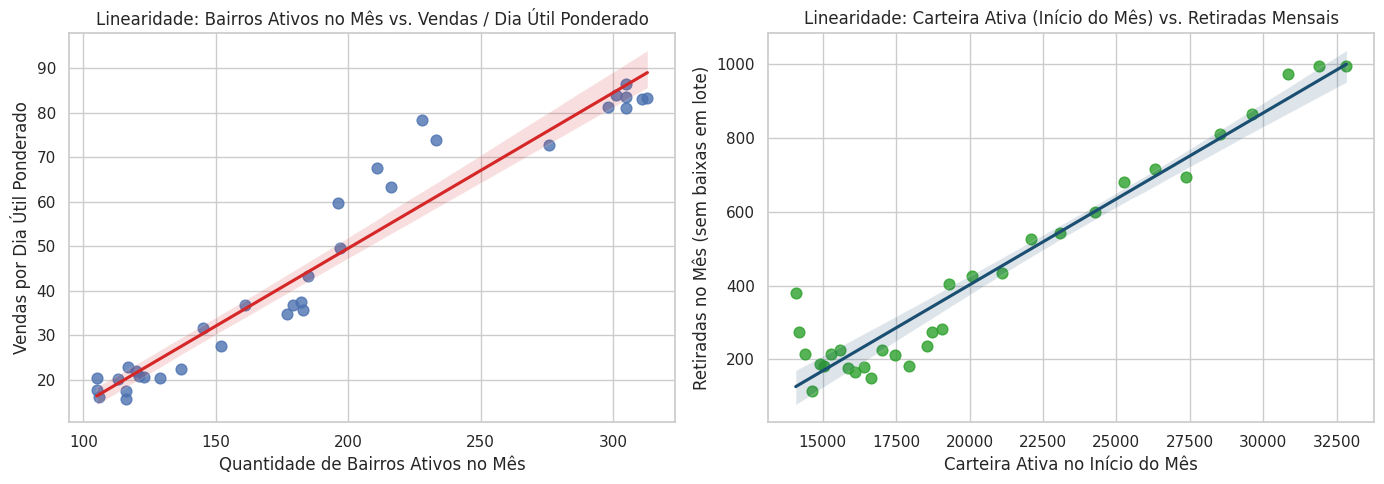

In [3]:
def calc_vif_table(df_in: pd.DataFrame, cols: list[str]) -> pd.DataFrame:
    X = df_in[cols].dropna().astype(float)
    X_const = np.column_stack([np.ones(len(X)), X.values])
    rows = []
    for i, c in enumerate(cols):
        rows.append({"feature": c, "VIF": round(float(variance_inflation_factor(X_const, i + 1)), 2)})
    return pd.DataFrame(rows)

print("=== VIF — Features de Vendas (Taxa por Dia Útil) ===")
display(calc_vif_table(df_closed, ["qtd_bairros_ativos_mes", "qtd_canais_ativos_mes", "vendas_por_du_lag1", "mes_sin", "mes_cos"]))

print("=== VIF — Features de Retiradas (Sem Anomalias de Lote) ===")
display(calc_vif_table(df_closed[df_closed["anomalia_retirada"] == 0], ["dias_uteis_ponderados", "carteira_inicio_mes", "vendas_acum_3m_ant", "retiradas_lag1", "mes_sin", "mes_cos"]))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.regplot(data=df_closed, x="qtd_bairros_ativos_mes", y="vendas_por_du", ax=axes[0], scatter_kws={"s": 60, "alpha": 0.8}, line_kws={"color": "#d62728"})
axes[0].set_title("Linearidade: Bairros Ativos no Mês vs. Vendas / Dia Útil Ponderado")
axes[0].set_xlabel("Quantidade de Bairros Ativos no Mês")
axes[0].set_ylabel("Vendas por Dia Útil Ponderado")

df_ret_ok = df_closed[df_closed["anomalia_retirada"] == 0]
sns.regplot(data=df_ret_ok, x="carteira_inicio_mes", y="retiradas", ax=axes[1], scatter_kws={"s": 60, "alpha": 0.8, "color": "#2ca02c"}, line_kws={"color": "#1b4f72"})
axes[1].set_title("Linearidade: Carteira Ativa (Início do Mês) vs. Retiradas Mensais")
axes[1].set_xlabel("Carteira Ativa no Início do Mês")
axes[1].set_ylabel("Retiradas no Mês (sem baixas em lote)")

plt.tight_layout()
plt.savefig(FIG_DIR / "02_relacoes_lineares_principais.png", dpi=140)
plt.show()
